<a href="https://colab.research.google.com/github/adilah-annisa/probabilitas-distribusi-python/blob/main/Probabilitas_Distribusi_Python_2455301005.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# CODINGAN EKSPLORASI DAN IMPLEMENTASI PYTHON (Adilah Annisa - 3 TI D)
# 1. Import Library dan Eksplorasi Library Singkat
import math, itertools, random
from fractions import Fraction
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate
import sympy as sp

# Generator acak numpy
rng = np.random.default_rng(42)
random.seed(42)
N = 100_000

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid":True, "grid.alpha":0.3})
pd.set_option("display.precision", 6)
print("Library siap digunakan. N simulasi =", f"{N:,}")

Library siap digunakan. N simulasi = 100,000


In [ ]:
# 2. Eksplorasi Library Python untuk Probabilitas Dasar
# 2a. math dan itertools (kombinatorik dan ruang sampel)
print("5!       =", math.factorial(5))
print("P(5,2)   =", math.perm(5, 2))
print("C(5,2)   =", math.comb(5, 2))
print("Permutasi 'ABC' ambil 2 :", list(itertools.permutations("ABC", 2)))
print("Kombinasi 'ABC' ambil 2 :", list(itertools.combinations("ABC", 2)))
print("Ruang sampel 2 koin     :", list(itertools.product("HT", repeat=2)))

5!       = 120
P(5,2)   = 20
C(5,2)   = 10
Permutasi 'ABC' ambil 2 : [('A', 'B'), ('A', 'C'), ('B', 'A'), ('B', 'C'), ('C', 'A'), ('C', 'B')]
Kombinasi 'ABC' ambil 2 : [('A', 'B'), ('A', 'C'), ('B', 'C')]
Ruang sampel 2 koin     : [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]


In [ ]:
# 2b. fractions dan sympy (peluang eksak tanpa galat pembulatan)
print("Fraction  : 6/36 =", Fraction(6, 36), "| 1/6 + 1/3 =", Fraction(1, 6) + Fraction(1, 3))
print("sympy     : 1/6 + 1/3 =", sp.Rational(1, 6) + sp.Rational(1, 3), "| C(5,2) =", sp.binomial(5, 2))

# Simbolik: P(A) + P(A^c) = 1
pA = sp.symbols("p_A")
print("sympy simbolik:", sp.simplify(pA + (1 - pA)))

Fraction  : 6/36 = 1/6 | 1/6 + 1/3 = 1/2
sympy     : 1/6 + 1/3 = 1/2 | C(5,2) = 10
sympy simbolik: 1


In [ ]:
# 2c. random, numpy.random, Counter (Membangkitkan Data Acak)
print("random.randint     :", random.randint(1, 6))
print("random.choice      :", random.choice(["Head", "Tail"]))
print("random.sample      :", random.sample(range(1, 50), 3), "(3 angka berbeda dari 1-49)")
dadu = rng.integers(1, 7, size=60)
print("numpy 10 lemparan  :", dadu[:10].tolist())
print("Counter 60 lemparan:", dict(sorted(Counter(dadu.tolist()).items())))

random.randint     : 6
random.choice      : Head
random.sample      : [38, 28, 3] (3 angka berbeda dari 1-49)
numpy 10 lemparan  : [3, 5, 4, 3, 6, 4, 1, 5, 4, 4]
Counter 60 lemparan: {1: 10, 2: 8, 3: 11, 4: 13, 5: 10, 6: 8}


In [ ]:
# 2d. scipy. stats ("pisau Swiss" distribusi Probabilitas)
d = stats.binom(n=5, p=0.5)          # banyak "Head" dari 5 lemparan koin adil
print("pmf(2) =", round(d.pmf(2), 4), "| cdf(2) =", round(d.cdf(2), 4),
      "| sf(2) =", round(d.sf(2), 4), "| ppf(0.5) =", int(d.ppf(0.5)))
print("mean, var =", d.mean(), d.var())
print("rvs (8 sampel):", d.rvs(size=8, random_state=1).tolist())
print("Cek manual pmf(2) = C(5,2)/2^5 =", math.comb(5, 2) / 2**5)

pmf(2) = 0.3125 | cdf(2) = 0.5 | sf(2) = 0.5 | ppf(0.5) = 2
mean, var = 2.5 1.25
rvs (8 sampel): [2, 3, 0, 2, 1, 1, 1, 2]
Cek manual pmf(2) = C(5,2)/2^5 = 0.3125


In [ ]:
# 3. Implemetasi pada Distribusi Probabilitas
# 3.0 Membuat Fungsi bantu yang akan dipakai berulang pada semua distribusi
# Sintaks untuk menampung hasil teori vs simulasi untuk tabel ringkasan di akhir
hasil = []   # menampung E[X] dan Var(X): teori vs simulasi

def plot_diskrit(dist, sampel, xs, judul, xlabel):
    xs = np.asarray(xs)
    emp = [np.mean(sampel == x) for x in xs]
    plt.bar(xs - 0.2, dist.pmf(xs), 0.4, label="PMF teori")
    plt.bar(xs + 0.2, emp, 0.4, label="Simulasi")
    plt.xlabel(xlabel); plt.ylabel("Peluang"); plt.title(judul); plt.legend(); plt.show()

def plot_kontinu(dist, sampel, judul, xlim, xlabel):
    xs = np.linspace(*xlim, 400)
    plt.hist(sampel, bins=60, range=xlim, density=True, alpha=0.5, label="Simulasi (histogram)")
    plt.plot(xs, dist.pdf(xs), "r", lw=2, label="PDF teori")
    plt.xlabel(xlabel); plt.ylabel("Kepadatan"); plt.title(judul); plt.legend(); plt.show()

Phi = lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2)))   # CDF Normal baku (manual)
print("Fungsi bantu siap.")

Fungsi bantu siap.


P(X=2)  : manual = 0.1937 | scipy = 0.1937 | simulasi = 0.1933
P(X>=3) : scipy  = 0.0702 | simulasi = 0.0704
E[X]    : rumus np = 1.00 | simulasi = 1.002
Var(X)  : rumus np(1-p) = 0.90 | simulasi = 0.899
Makna   : rata-rata 1 request error per 10 request. Peluang 3 error atau lebih hanya 7.0%, jadi bisa dipakai sebagai ambang alert pada dashboard monitoring.


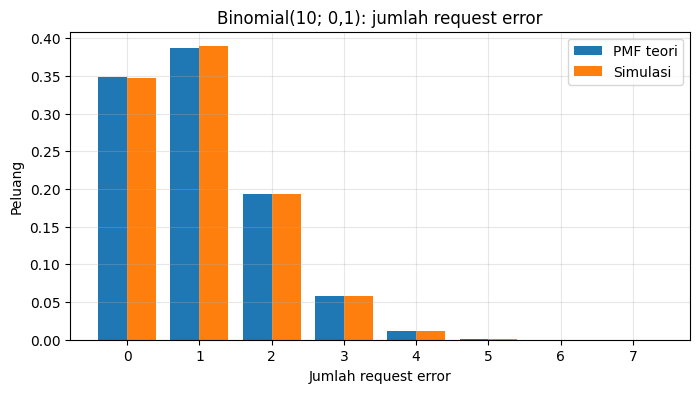

In [ ]:
# A. Penerapan pada Distribusi Diskrit
# 3a. Distribusi Binomial
n, p = 10, 0.1
X = stats.binom(n, p)                          # distribusi Binomial
sam = rng.binomial(n, p, size=N)               # simulasi N kali "kirim 10 request"

manual = math.comb(n, 2) * p**2 * (1 - p)**(n - 2)
print(f"P(X=2)  : manual = {manual:.4f} | scipy = {X.pmf(2):.4f} | simulasi = {np.mean(sam == 2):.4f}")
print(f"P(X>=3) : scipy  = {X.sf(2):.4f} | simulasi = {np.mean(sam >= 3):.4f}")
print(f"E[X]    : rumus np = {n*p:.2f} | simulasi = {sam.mean():.3f}")
print(f"Var(X)  : rumus np(1-p) = {n*p*(1-p):.2f} | simulasi = {sam.var(ddof=1):.3f}")
print(f"Makna   : rata-rata {n*p:.0f} request error per 10 request. Peluang 3 error atau lebih hanya {X.sf(2):.1%}, "
      f"jadi bisa dipakai sebagai ambang alert pada dashboard monitoring.")

hasil.append(("Binomial", X.mean(), sam.mean(), X.var(), sam.var(ddof=1)))
plot_diskrit(X, sam, range(0, 8), "Binomial(10; 0,1): jumlah request error", "Jumlah request error")

P(X=3)  : manual = 0.0630 | scipy = 0.0630 | simulasi = 0.0630
P(X<=3) : manual = 0.9730 | scipy = 0.9730 | simulasi = 0.9725
E[X]    : rumus 1/p = 1.4286 | simulasi = 1.4288
Var(X)  : rumus (1-p)/p^2 = 0.6122 | simulasi = 0.6153
Makna   : rata-rata paket dikirim 1.43 kali. Sebanyak 97.3% paket berhasil dalam 3 kali kirim, sehingga batas retry maksimum = 3 sudah cukup.


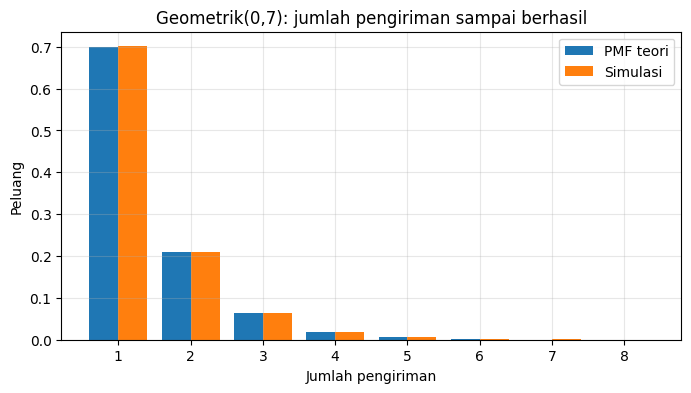

In [ ]:
# 3b. Distribusi Geometrik
p = 0.7
X = stats.geom(p)                              # distribusi Geometrik (k = 1, 2, 3, ...)
sam = X.rvs(size=N, random_state=rng)          # simulasi N paket

print(f"P(X=3)  : manual = {(1-p)**2 * p:.4f} | scipy = {X.pmf(3):.4f} | simulasi = {np.mean(sam == 3):.4f}")
print(f"P(X<=3) : manual = {1 - (1-p)**3:.4f} | scipy = {X.cdf(3):.4f} | simulasi = {np.mean(sam <= 3):.4f}")
print(f"E[X]    : rumus 1/p = {1/p:.4f} | simulasi = {sam.mean():.4f}")
print(f"Var(X)  : rumus (1-p)/p^2 = {(1-p)/p**2:.4f} | simulasi = {sam.var(ddof=1):.4f}")
print(f"Makna   : rata-rata paket dikirim {1/p:.2f} kali. Sebanyak {X.cdf(3):.1%} paket berhasil dalam 3 kali kirim, "
      f"sehingga batas retry maksimum = 3 sudah cukup.")

hasil.append(("Geometrik", X.mean(), sam.mean(), X.var(), sam.var(ddof=1)))
plot_diskrit(X, sam, range(1, 9), "Geometrik(0,7): jumlah pengiriman sampai berhasil", "Jumlah pengiriman")

In [ ]:
# 3c. Distribusi Poisson

P(3<X<7): manual = 0.400 | scipy = 0.400 | integral = 0.400 | simulasi = 0.3987
E[X]    : rumus (a+b)/2 = 5.0 | simulasi = 5.006
Var(X)  : rumus (b-a)^2/12 = 8.333 | simulasi = 8.321
Makna   : peluang hanya bergantung pada lebar rentang (4 ms dari 10 ms = 40%), bukan posisinya. Backoff acak membuat dua perangkat jarang memilih waktu yang sama.


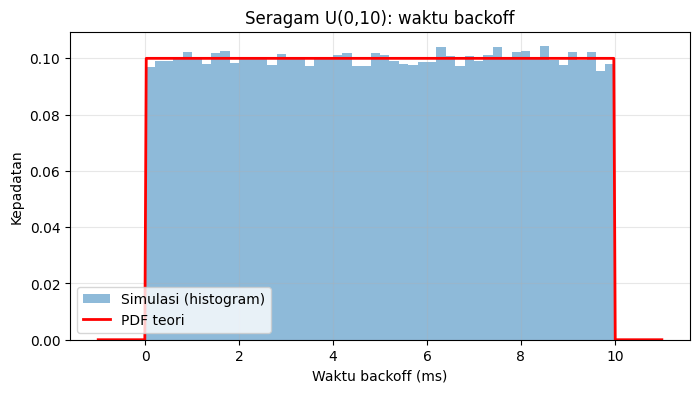

In [ ]:
# B. Distribusi Kontinu
# 3d. Distribusi Seragam (Uniform)
a, b = 0, 10
X = stats.uniform(loc=a, scale=b - a)          # U(0, 10)
sam = X.rvs(size=N, random_state=rng)

print(f"P(3<X<7): manual = {(7-3)/(b-a):.3f} | scipy = {X.cdf(7) - X.cdf(3):.3f} "
      f"| integral = {integrate.quad(X.pdf, 3, 7)[0]:.3f} | simulasi = {np.mean((sam > 3) & (sam < 7)):.4f}")
print(f"E[X]    : rumus (a+b)/2 = {(a+b)/2} | simulasi = {sam.mean():.3f}")
print(f"Var(X)  : rumus (b-a)^2/12 = {(b-a)**2/12:.3f} | simulasi = {sam.var(ddof=1):.3f}")
print("Makna   : peluang hanya bergantung pada lebar rentang (4 ms dari 10 ms = 40%), bukan posisinya. "
      "Backoff acak membuat dua perangkat jarang memilih waktu yang sama.")

hasil.append(("Seragam", X.mean(), sam.mean(), X.var(), sam.var(ddof=1)))
plot_kontinu(X, sam, "Seragam U(0,10): waktu backoff", (-1, 11), "Waktu backoff (ms)")

P(X>1500) : manual = 0.2231 | scipy = 0.2231 | simulasi = 0.2227
P(X<=500) : manual = 0.3935 | scipy = 0.3935 | simulasi = 0.3929
E[X]      : rumus 1/lambda = 1000 | simulasi = 997.2
Var(X)    : rumus 1/lambda^2 = 1,000,000 | simulasi = 986,124
Makna     : 22.3% server masih hidup setelah 1500 jam, dan 39.3% rusak dalam 500 jam pertama. Median umur server = 693 jam, lebih kecil dari rata-rata karena sebagian kecil server bisa sangat awet.


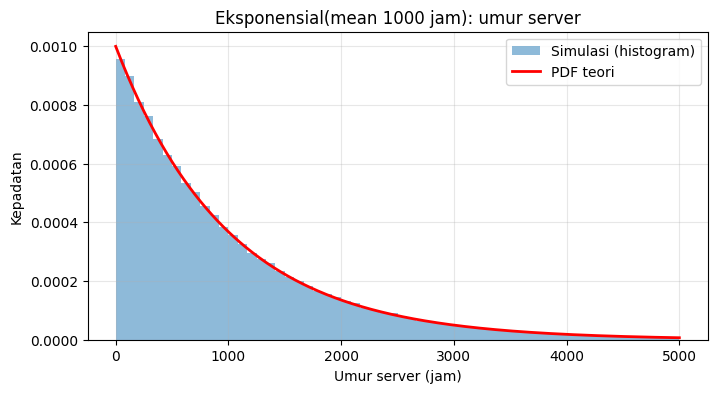

In [ ]:
# 3e. Distribusi Eksponensial
rata2 = 1000                                   # MTBF = 1000 jam
X = stats.expon(scale=rata2)                   # scale = 1/lambda
sam = X.rvs(size=N, random_state=rng)

print(f"P(X>1500) : manual = {math.exp(-1.5):.4f} | scipy = {X.sf(1500):.4f} | simulasi = {np.mean(sam > 1500):.4f}")
print(f"P(X<=500) : manual = {1 - math.exp(-0.5):.4f} | scipy = {X.cdf(500):.4f} | simulasi = {np.mean(sam <= 500):.4f}")
print(f"E[X]      : rumus 1/lambda = {rata2} | simulasi = {sam.mean():.1f}")
print(f"Var(X)    : rumus 1/lambda^2 = {rata2**2:,} | simulasi = {sam.var(ddof=1):,.0f}")
print(f"Makna     : {X.sf(1500):.1%} server masih hidup setelah 1500 jam, dan {X.cdf(500):.1%} rusak dalam 500 jam pertama. "
      f"Median umur server = {X.median():.0f} jam, lebih kecil dari rata-rata karena sebagian kecil server bisa sangat awet.")

hasil.append(("Eksponensial", X.mean(), sam.mean(), X.var(), sam.var(ddof=1)))
plot_kontinu(X, sam, "Eksponensial(mean 1000 jam): umur server", (0, 5000), "Umur server (jam)")

P(X>250)       : manual = 0.0478 | scipy = 0.0478 | simulasi = 0.0476
P(170<X<230)   : manual = 0.6827 | scipy = 0.6827 | simulasi = 0.6805
Persentil 99   : manual = 269.8 ms | scipy = 269.8 ms | simulasi = 269.7 ms
E[X] = 200 | simulasi = 199.93   ;   Var(X) = 900 | simulasi = 903.1
Makna          : hanya 4.8% request lebih lambat dari 250 ms, dan SLO "99% request di bawah 270 ms" dapat dipenuhi oleh layanan ini.


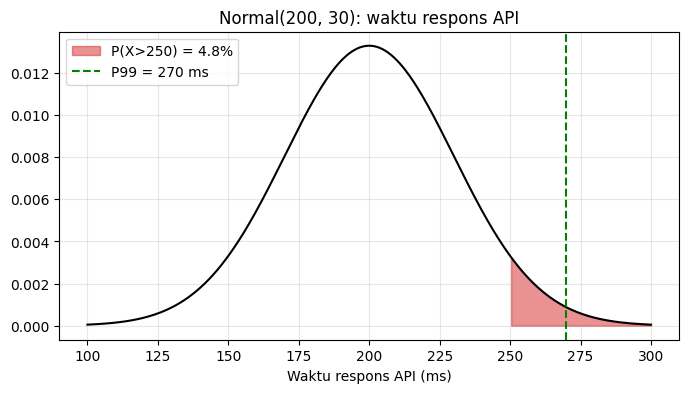

In [ ]:
# 3f. Distribusi Normal
mu, sigma = 200, 30
X = stats.norm(mu, sigma)
sam = X.rvs(size=N, random_state=rng)

z = (250 - mu) / sigma
print(f"P(X>250)       : manual = {1 - Phi(z):.4f} | scipy = {X.sf(250):.4f} | simulasi = {np.mean(sam > 250):.4f}")
print(f"P(170<X<230)   : manual = {Phi(1) - Phi(-1):.4f} | scipy = {X.cdf(230) - X.cdf(170):.4f} | simulasi = {np.mean((sam > 170) & (sam < 230)):.4f}")
print(f"Persentil 99   : manual = {mu + 2.326*sigma:.1f} ms | scipy = {X.ppf(0.99):.1f} ms | simulasi = {np.percentile(sam, 99):.1f} ms")
print(f"E[X] = {mu} | simulasi = {sam.mean():.2f}   ;   Var(X) = {sigma**2} | simulasi = {sam.var(ddof=1):.1f}")
print(f"Makna          : hanya {X.sf(250):.1%} request lebih lambat dari 250 ms, dan SLO \"99% request di bawah "
      f"{X.ppf(0.99):.0f} ms\" dapat dipenuhi oleh layanan ini.")

hasil.append(("Normal", X.mean(), sam.mean(), X.var(), sam.var(ddof=1)))
xs = np.linspace(100, 300, 400)
plt.plot(xs, X.pdf(xs), "k")
plt.fill_between(xs, X.pdf(xs), where=xs > 250, color="tab:red", alpha=0.5, label=f"P(X>250) = {X.sf(250):.1%}")
plt.axvline(X.ppf(0.99), color="g", ls="--", label=f"P99 = {X.ppf(0.99):.0f} ms")
plt.xlabel("Waktu respons API (ms)"); plt.title("Normal(200, 30): waktu respons API"); plt.legend(); plt.show()

In [ ]:
# Tabel Perbandingan Nilai Harapan dan Varians Hasil Rumus
tab = pd.DataFrame(hasil, columns=["Distribusi", "E[X] teori", "E[X] simulasi", "Var teori", "Var simulasi"]).set_index("Distribusi")
tab["Galat E[X] (%)"] = 100 * (tab["E[X] simulasi"] - tab["E[X] teori"]).abs() / tab["E[X] teori"]
tab["Galat Var (%)"] = 100 * (tab["Var simulasi"] - tab["Var teori"]).abs() / tab["Var teori"]
display(tab.round(4))
print(f"Galat terbesar: nilai harapan = {tab['Galat E[X] (%)'].max():.2f}% | varians = {tab['Galat Var (%)'].max():.2f}%")

,E[X] teori,E[X] simulasi,Var teori,Var simulasi,Galat E[X] (%),Galat Var (%)
Distribusi,,,,,,
Binomial,1.0000,1.0018,0.9000,0.8994,0.1790,0.0716
Geometrik,1.4286,1.4288,0.6122,0.6153,0.0160,0.5017
Seragam,5.0000,5.0060,8.3333,8.3212,0.1194,0.1453
Eksponensial,1000.0000,997.2173,1000000.0000,986124.2169,0.2783,1.3876
Normal,200.0000,199.9321,900.0000,903.0878,0.0339,0.3431


Galat terbesar: nilai harapan = 0.28% | varians = 1.39%
